# Paso 1 · Definición del problema y análisis ético

| | |
|---|---|
| **IDs del enunciado** | IA1.1 (explorar datasets y definir el problema), IA1.3 (análisis ético), E5 (problema en contexto), F1 (definir el problema) |
| **Fase** | F1 · Definir el problema (CRISP-DM: *Business Understanding*) |
| **Historia** | HU-01 · Sprint S6 (origen en S1) |
| **Entregable** | este notebook + `Back/reports/variables_sensibles.json` (tabla que reutiliza el paso 8) |

Estructura: **1. Contexto · 2. Formulación · 3. Datasets · 4. Métricas · 5. Ética · 6. Carga inicial · Conclusiones**

**Aprendizaje de la unidad (Módulo 2 · Unidad 1).** Antes de entrenar un modelo hay que saber *para qué*
decide y *a quién* afecta. En lo conceptual: una probabilidad de impago solo es útil si se traduce en una
acción con costos explícitos (aprobar, revisar o rechazar), y un modelo de crédito puede discriminar aunque
no use la variable sensible, por medio de *proxies* o de etiquetas históricas sesgadas. En lo práctico:
formular el problema como clasificación binaria, elegir métricas coherentes con la política de costos,
dejar escrita la tabla de variables sensibles que se auditará en el paso 8 y validar el contrato de datos
con el paquete `credit_risk`.

In [1]:
FAST = False

In [2]:
# Parameters
FAST = False


In [3]:
from credit_risk.notebook import setup

ENTORNO = setup()
ENTORNO

{'entorno': 'Jupyter local',
 'kernel': 'credit-risk',
 'semilla': 42,
 'versiones': {'python': '3.10.7',
  'pandas': '2.3.3',
  'numpy': '1.26.4',
  'matplotlib': '3.10.9',
  'seaborn': '0.13.2',
  'scikit-learn': '1.4.2',
  'duckdb': '1.5.6',
  'plotnine': '0.15.8'}}

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from credit_risk import config
from credit_risk.data import cargar_datos, validar_dataset
from credit_risk.fairness import grupo_edad
from credit_risk.models import Costos, banda, decidir, umbrales_chow
from credit_risk.notebook import ruta
from credit_risk.reporting import PALETA, figura_front, guardar_json

COSTOS = Costos()
UMBRALES = umbrales_chow(COSTOS)
print(f"Costos por unidad de exposición (ADR-002): C_FN={COSTOS.fn} · C_FP={COSTOS.fp} · C_R={COSTOS.revision}")
print(f"Umbrales de Chow: aprobar si p < {UMBRALES.aprobar:.4f} · rechazar si p > {UMBRALES.rechazar:.4f}"
      f" · referencia de dos acciones {UMBRALES.bayes:.2f}")

Costos por unidad de exposición (ADR-002): C_FN=0.45 · C_FP=0.15 · C_R=0.08
Umbrales de Chow: aprobar si p < 0.1778 · rechazar si p > 0.4667 · referencia de dos acciones 0.25


## 1. Contexto de negocio

Una institución financiera colombiana recibe miles de solicitudes de crédito de consumo al mes. Antes de
desembolsar necesita estimar la **probabilidad de impago (PD, *probability of default*)** de cada solicitante.

- **Quién usa el modelo:** el **analista de crédito** y el motor de decisión de la originación. El modelo no
  decide solo: las solicitudes dudosas pasan a revisión humana.
- **Decisión que apoya:** **aprobar**, **enviar a revisión manual** o **rechazar** (regla de Chow, ADR-002).
- **Costo de cada error**, por unidad de exposición (valores de `credit_risk.config`, justificados en ADR-002):

| Situación | Qué ocurre | Costo para el negocio | Costo para la persona |
|---|---|---|---|
| **Falso negativo** (se aprueba y el cliente incumple) | Crédito que no se recupera | `C_FN = LGD = 0,45` (pérdida dado el impago de Basilea F-IRB) | Sobreendeudamiento y reporte negativo en centrales |
| **Falso positivo** (se rechaza a quien habría pagado) | Se pierde un buen cliente | `C_FP = 0,15` (margen financiero perdido) | **Exclusión financiera** injusta |
| **Revisión manual** | Un analista estudia la solicitud | `C_R = 0,08` (tiempo del analista, abandono por demora y error residual) | Demora en la respuesta |

Aprobar a quien no paga cuesta **3 veces** más que rechazar a quien sí paga (0,45 frente a 0,15). Por eso el
umbral no es 0,5: la tabla siguiente, calculada con `credit_risk.models.umbrales_chow`, muestra la política.

In [5]:
politica = pd.DataFrame([
    {"accion": "aprobar", "banda": "Bajo", "condicion": f"p < C_R/C_FN = {UMBRALES.aprobar:.4f}",
     "costo_esperado": "p · C_FN (se asume el riesgo)"},
    {"accion": "revisar", "banda": "Medio", "condicion": f"{UMBRALES.aprobar:.4f} ≤ p ≤ {UMBRALES.rechazar:.4f}",
     "costo_esperado": "C_R (lo decide un analista)"},
    {"accion": "rechazar", "banda": "Alto", "condicion": f"p > 1 − C_R/C_FP = {UMBRALES.rechazar:.4f}",
     "costo_esperado": "(1 − p) · C_FP (margen perdido)"},
]).set_index("accion")
politica

,banda,condicion,costo_esperado
accion,,,
aprobar,Bajo,p < C_R/C_FN = 0.1778,p · C_FN (se asume el riesgo)
revisar,Medio,0.1778 ≤ p ≤ 0.4667,C_R (lo decide un analista)
rechazar,Alto,p > 1 − C_R/C_FP = 0.4667,(1 − p) · C_FP (margen perdido)


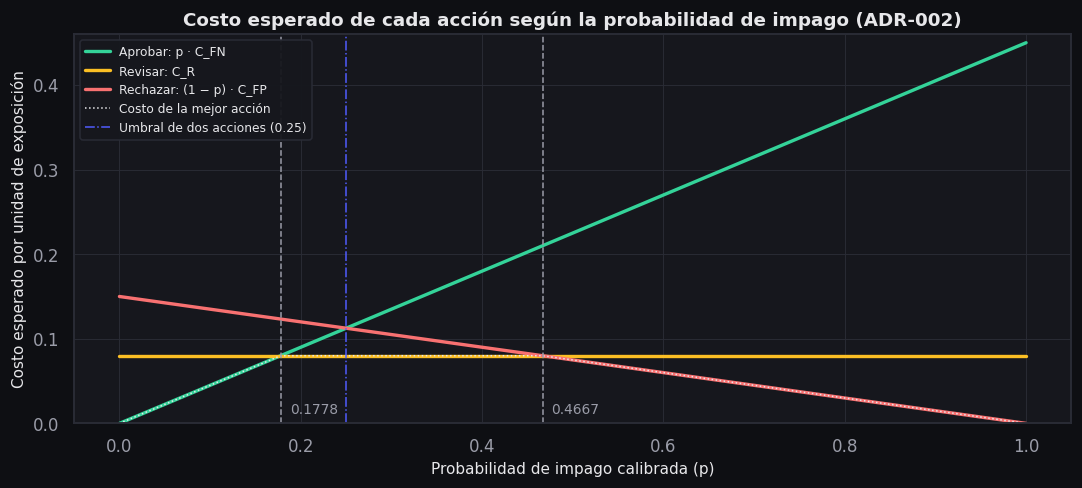

In [6]:
p = np.linspace(0, 1, 201)
costos_accion = {"Aprobar: p · C_FN": p * COSTOS.fn, "Revisar: C_R": np.full_like(p, COSTOS.revision),
                 "Rechazar: (1 − p) · C_FP": (1 - p) * COSTOS.fp}
costos_accion["Costo de la mejor acción"] = np.minimum.reduce(list(costos_accion.values()))
fig, ax = plt.subplots(figsize=(10, 4.6))
for (nombre, c), color in zip(costos_accion.items(), [PALETA["bajo"], PALETA["medio"], PALETA["alto"], PALETA["texto"]]):
    mejor = nombre.startswith("Costo")
    ax.plot(p, c, color=color, lw=1 if mejor else 2.2, ls=":" if mejor else "-", label=nombre)
for x, nombre in [(UMBRALES.aprobar, "aprobar"), (UMBRALES.rechazar, "rechazar")]:
    ax.axvline(x, color=PALETA["texto_suave"], ls="--", lw=1)
    ax.text(x + 0.01, 0.012, f"{x:.4f}", color=PALETA["texto_suave"], fontsize=9)
ax.axvline(UMBRALES.bayes, color=PALETA["acento"], ls="-.", lw=1, label=f"Umbral de dos acciones ({UMBRALES.bayes:.2f})")
ax.set(title="Costo esperado de cada acción según la probabilidad de impago (ADR-002)",
       xlabel="Probabilidad de impago calibrada (p)", ylabel="Costo esperado por unidad de exposición",
       ylim=(0, 0.46))
ax.legend(fontsize=8, loc="upper left", framealpha=0.95)
plt.show()
figura_front("lineas", "Costo esperado de cada acción según la probabilidad de impago (ADR-002)",
             {"series": [{"nombre": n, "x": p.round(4).tolist(), "y": c.round(4).tolist()} for n, c in costos_accion.items()],
              "referencias": [{"eje": "x", "valor": round(UMBRALES.aprobar, 4), "etiqueta": "Aprobar si p <"},
                              {"eje": "x", "valor": round(UMBRALES.rechazar, 4), "etiqueta": "Rechazar si p >"},
                              {"eje": "x", "valor": round(UMBRALES.bayes, 4), "etiqueta": "Umbral de dos acciones"}],
              "bandas": [{"desde": 0, "hasta": round(UMBRALES.aprobar, 4), "etiqueta": "Aprobar (Bajo)"},
                         {"desde": round(UMBRALES.aprobar, 4), "hasta": round(UMBRALES.rechazar, 4), "etiqueta": "Revisar (Medio)"},
                         {"desde": round(UMBRALES.rechazar, 4), "hasta": 1, "etiqueta": "Rechazar (Alto)"}]},
             ejes={"x": "Probabilidad de impago calibrada (p)", "y": "Costo esperado por unidad de exposición"},
             clave="costo_por_accion", opciones={"formato_x": "dec3", "formato_y": "dec3", "color_por": "banda"})

**Interpretación.** Para cada probabilidad se elige la acción de menor costo esperado (línea punteada). Por
debajo de **0,1778** aprobar es lo más barato; por encima de **0,4667** lo es rechazar; entre ambos valores la
revisión manual (0,08) cuesta menos que equivocarse de forma automática. El umbral de dos acciones (0,25) cae
dentro de la zona de revisión: es justo donde el modelo está menos seguro. La regla solo es válida si las
probabilidades están **calibradas**, lo que convierte la calibración (Brier) en un requisito y no en un adorno.

## 2. Formulación técnica

| Elemento | Definición |
|---|---|
| Tipo de problema | **Clasificación binaria supervisada** |
| Unidad de análisis | Una solicitud de crédito (un cliente) |
| Variable objetivo | `default` (1 = impago, 0 = pagó) |
| Variables de entrada | 12 numéricas y 5 categóricas (`config.INPUT_COLS`): demográficas, laborales, financieras y de buró; el texto libre se evalúa aparte en el paso 7 |
| Salida del modelo | Una **probabilidad** de impago calibrada en [0, 1], **una banda** (Bajo, Medio, Alto) y **una acción** (aprobar, revisar, rechazar) |
| Bandas | Coinciden con las acciones por construcción: Bajo ↔ aprobar, Medio ↔ revisar, Alto ↔ rechazar |
| Excluidas como predictor | `id_cliente` (identificador) y `sexo` (sensible: solo se usa para auditar) |

La celda siguiente traduce probabilidades de ejemplo con las funciones que usa la API (`decidir` y `banda`).

In [7]:
ejemplos = np.array([0.05, 0.17, 0.25, 0.40, 0.60, 0.90])
pd.DataFrame({"probabilidad_impago": ejemplos, "accion": decidir(ejemplos, UMBRALES),
              "banda": banda(ejemplos, UMBRALES)})

,probabilidad_impago,accion,banda
0,0.0500,aprobar,Bajo
1,0.1700,aprobar,Bajo
2,0.2500,revisar,Medio
3,0.4000,revisar,Medio
4,0.6000,rechazar,Alto
5,0.9000,rechazar,Alto


## 3. Exploración de datasets financieros

**Fuente usada:** `db/credit_risk.csv` (ver `docs/diccionario_datos.md`). Es un dataset **sintético
realista**, generado con semilla 42 y ambientado en Colombia (montos en COP, puntaje de buró tipo
DataCrédito), con estructura inspirada en *German Credit* y *Default of Credit Card Clients* (UCI). Trae
imperfecciones intencionales (nulos, duplicados, atípicos, edades inválidas) y una columna de **texto libre**
en español. La fila propia de la tabla se llena con los datos leídos; las de los datasets públicos resumen
su documentación oficial.

In [8]:
df = cargar_datos()
if FAST:
    df = df.sample(3000, random_state=config.RANDOM_STATE).reset_index(drop=True)
datasets = pd.DataFrame([
    {"dataset": "credit_risk.csv (elegido)", "fuente": "Sintético propio (db/generacion)",
     "filas": f"{len(df):,}", "columnas": df.shape[1], "tasa_impago": f"{df[config.TARGET].mean():.1%}",
     "variables_sensibles": "sexo, edad, estado civil", "texto_libre": "Sí (español)",
     "limitacion": "Sintético: relaciones plausibles, no observadas en un banco real"},
    {"dataset": "German Credit", "fuente": "UCI ML Repository (1994)", "filas": "1,000", "columnas": 21,
     "tasa_impago": "30,0 %", "variables_sensibles": "sexo + estado civil (combinados), edad, extranjero",
     "texto_libre": "No", "limitacion": "Muy pequeño, codificado (A11, A12…), en marcos alemanes"},
    {"dataset": "Default of Credit Card Clients", "fuente": "UCI ML Repository (Taiwán, 2005)",
     "filas": "30,000", "columnas": 24, "tasa_impago": "22,1 %",
     "variables_sensibles": "sexo, edad, estado civil", "texto_libre": "No",
     "limitacion": "Solo tarjetas de crédito; impago del mes siguiente; contexto taiwanés"},
    {"dataset": "Give Me Some Credit", "fuente": "Kaggle (2011)", "filas": "150,000", "columnas": 11,
     "tasa_impago": "6,7 %", "variables_sensibles": "edad", "texto_libre": "No",
     "limitacion": "Pocas variables, sin demografía rica; licencia de competencia"},
]).set_index("dataset")
datasets

,fuente,filas,columnas,tasa_impago,variables_sensibles,texto_libre,limitacion
dataset,,,,,,,
credit_risk.csv (elegido),Sintético propio (db/generacion),"12,144",21,35.6%,"sexo, edad, estado civil",Sí (español),"Sintético: relaciones plausibles, no observada..."
German Credit,UCI ML Repository (1994),"1,000",21,"30,0 %","sexo + estado civil (combinados), edad, extran...",No,"Muy pequeño, codificado (A11, A12…), en marcos..."
Default of Credit Card Clients,"UCI ML Repository (Taiwán, 2005)","30,000",24,"22,1 %","sexo, edad, estado civil",No,Solo tarjetas de crédito; impago del mes sigui...
Give Me Some Credit,Kaggle (2011),"150,000",11,"6,7 %",edad,No,"Pocas variables, sin demografía rica; licencia..."


**Justificación de la elección.** El dataset propio es el único de la tabla que permite cubrir **todas**
las unidades del curso con un solo conjunto de datos: limpieza (nulos, duplicados y atípicos), codificación
(nominales y una ordinal), NLP (texto en español), auditoría de equidad (sexo, edad y estado civil por
separado) y un contexto de negocio colombiano coherente. Al ser sintético **no expone datos personales
reales** (Ley 1581 de 2012) y permite controlar cada imperfección que el pipeline debe resolver. Además, el
paso 5 replica la metodología en *German Credit* (datos reales) como verificación externa.

## 4. Métricas de éxito y su relación con la política de costos

| Métrica | Rol | Por qué | Relación con la política |
|---|---|---|---|
| **ROC-AUC** | **Principal** | Capacidad de *ordenar* a los clientes por riesgo, sin depender del umbral | Si el orden es malo, ningún umbral de Chow separa bien aprobar de rechazar |
| Recall de la clase impago | Secundaria | Fracción de impagos detectados | Controla el error más caro (`C_FN = 0,45`) |
| F1 de la clase impago | Secundaria | Equilibrio entre precisión y recall con clases desbalanceadas | Se reporta al umbral de dos acciones 0,25 para comparar modelos |
| **KS** (Kolmogorov-Smirnov) | Secundaria | Máxima separación entre las distribuciones de score de buenos y malos | Métrica habitual en *scoring* bancario |
| **Brier score** | Secundaria | Calidad de la **probabilidad** (calibración) | Los umbrales 0,1778 y 0,4667 suponen probabilidades calibradas |

**Meta mínima:** **ROC-AUC ≥ 0,70 en el conjunto de prueba**, por encima de la línea base
(`DummyClassifier`, AUC = 0,5). La métrica de negocio que decide entre variantes (paso 8) es el **costo
esperado por solicitud** con la regla de Chow, sujeto a la restricción de equidad del apartado 5.

## 5. Análisis ético

### 5.1 Variables sensibles

La tabla queda **definida aquí y se reutiliza en el paso 8** (auditoría de equidad). Se guarda en
`Back/reports/variables_sensibles.json`. Los grupos de edad son los fijos de `config.GRUPOS_EDAD_LABELS`
(ADR-003), los mismos que usa `credit_risk.fairness.auditar`.

In [9]:
VARIABLES_SENSIBLES = pd.DataFrame([
    {"variable": "sexo", "tipo": "protegida (sexo)", "uso_en_modelo": "NO: solo auditoría",
     "grupos_auditoria": " / ".join(config.CATEGORIAS["sexo"]),
     "auditoria_paso_8": "DI de la aprobación automática con IC bootstrap 95 %",
     "riesgo": "Discriminación directa por sexo"},
    {"variable": "edad", "tipo": "protegida (edad)", "uso_en_modelo": "Sí, auditada (variante sin_edad)",
     "grupos_auditoria": " / ".join([*config.GRUPOS_EDAD_LABELS, config.GRUPO_EDAD_DESCONOCIDO]),
     "auditoria_paso_8": "DI con IC, igualdad de oportunidades; variantes sin_edad y reweighing",
     "riesgo": "Penalizar a jóvenes o a adultos mayores"},
    {"variable": "estado_civil", "tipo": "sensible (situación familiar)", "uso_en_modelo": "Sí, vigilada",
     "grupos_auditoria": " / ".join(config.CATEGORIAS["estado_civil"]),
     "auditoria_paso_8": "Tasa observada por grupo (descriptiva; fuera del criterio DI de ADR-003)",
     "riesgo": "Discriminación por situación familiar"},
    {"variable": "personas_a_cargo", "tipo": "proxy potencial", "uso_en_modelo": "Sí, vigilada",
     "grupos_auditoria": "-", "auditoria_paso_8": "Importancia y explicaciones (SHAP)",
     "riesgo": "Proxy de sexo o de estado civil"},
    {"variable": "tipo_vivienda", "tipo": "proxy socioeconómico", "uso_en_modelo": "Sí, vigilada",
     "grupos_auditoria": "-", "auditoria_paso_8": "Importancia y explicaciones (SHAP)",
     "riesgo": "Proxy de nivel socioeconómico"},
    {"variable": "texto_solicitud", "tipo": "texto libre", "uso_en_modelo": "No en el modelo servido (paso 7)",
     "grupos_auditoria": "-", "auditoria_paso_8": "-",
     "riesgo": "Puede revelar datos sensibles o sesgos de redacción"},
]).set_index("variable")
EXCLUIDAS_DEL_MODELO = [config.ID_COL, config.SENSITIVE_COL]
destino = guardar_json(VARIABLES_SENSIBLES.reset_index(), config.REPORTS_DIR / "variables_sensibles.json")
print(f"Tabla guardada en {ruta(destino)} · excluidas del modelo: {EXCLUIDAS_DEL_MODELO}")
VARIABLES_SENSIBLES

Tabla guardada en Back/reports/variables_sensibles.json · excluidas del modelo: ['id_cliente', 'sexo']


,tipo,uso_en_modelo,grupos_auditoria,auditoria_paso_8,riesgo
variable,,,,,
sexo,protegida (sexo),NO: solo auditoría,M / F,DI de la aprobación automática con IC bootstra...,Discriminación directa por sexo
edad,protegida (edad),"Sí, auditada (variante sin_edad)",18-29 / 30-59 / 60+ / desconocida,"DI con IC, igualdad de oportunidades; variante...",Penalizar a jóvenes o a adultos mayores
estado_civil,sensible (situación familiar),"Sí, vigilada",Soltero / Casado / Union_libre / Divorciado / ...,Tasa observada por grupo (descriptiva; fuera d...,Discriminación por situación familiar
personas_a_cargo,proxy potencial,"Sí, vigilada",-,Importancia y explicaciones (SHAP),Proxy de sexo o de estado civil
tipo_vivienda,proxy socioeconómico,"Sí, vigilada",-,Importancia y explicaciones (SHAP),Proxy de nivel socioeconómico
texto_solicitud,texto libre,No en el modelo servido (paso 7),-,-,Puede revelar datos sensibles o sesgos de reda...


### 5.2 Riesgos identificados

1. **Sesgo histórico en las etiquetas:** si en el pasado se negó crédito a ciertos grupos, el `default`
   observado refleja esas decisiones y el modelo puede perpetuarlas.
2. **Discriminación indirecta por *proxies*:** aunque se retire `sexo`, otras variables (personas a cargo,
   estado civil, tipo de vivienda, redacción del texto) pueden reconstruirlo.
3. **Falta de explicabilidad:** un rechazo sin motivos vulnera el derecho del solicitante a conocerlos y
   dificulta la supervisión.
4. **Privacidad:** ingresos, deudas y buró son datos personales; su uso exige finalidad legítima,
   autorización, minimización y seguridad.

### 5.3 Medidas de mitigación

| Medida | Cómo se implementa | Paso |
|---|---|---|
| `sexo` fuera del modelo | `config.SENSITIVE_COL` no entra en `config.INPUT_COLS`; solo se usa para auditar | 3, 8 |
| Medir la equidad sobre la **decisión** | *Disparate impact* de la **aprobación automática** (`p < 0,1778`) por sexo y edad, con IC bootstrap; alerta si DI < 0,8 | 8 |
| Mitigar sin trato dispar | Variantes `sin_edad` y *reweighing*; **no** se usan umbrales distintos por grupo (ADR-003) | 8 |
| Explicaciones exactas | Contribuciones en log-odds del modelo lineal servido, devueltas por la API en cada predicción | 8, 10 |
| Humano en el ciclo | La banda Medio se envía a revisión manual del analista | 8, 10 |
| Anonimizar | `id_cliente` es un código sin datos personales (`CLI_xxxxxx`); no hay nombres ni documentos | 1 |

### 5.4 Referencia normativa

- **Ley 1581 de 2012 (Colombia)** y Decreto 1377 de 2013: protección de datos personales (finalidad,
  libertad, veracidad, transparencia, acceso, seguridad y confidencialidad).
- **Ley 1266 de 2008 (*habeas data* financiero):** uso de la información de las centrales de riesgo.
- **Principios de IA responsable** (OCDE, 2019; marco ético para la IA de Colombia, 2021): equidad,
  transparencia, explicabilidad, responsabilidad y supervisión humana.
- La regla de las 4/5 (DI ≥ 0,8) es una heurística de la EEOC (EE. UU.); aquí se usa como **alerta**, no
  como norma colombiana.

## 6. Carga inicial y validación del contrato de datos

Solo se confirma la forma del archivo, sus columnas y la tasa de `default`; la exploración completa está en
el notebook 02. `validar_dataset` comprueba el contrato de `docs/03_contrato_datos.md`.

In [10]:
print(f"Archivo: {ruta(config.RAW_DATA_PATH)}")
print(f"Filas: {df.shape[0]:,} · columnas: {df.shape[1]}")
print("Columnas:", ", ".join(df.columns))
print(f"Tasa de default: {df[config.TARGET].mean():.2%}")
df[config.TARGET].value_counts().rename(index={0: "Pagó (0)", 1: "Impago (1)"}).to_frame("clientes")

Archivo: db/credit_risk.csv
Filas: 12,144 · columnas: 21
Columnas: id_cliente, edad, sexo, estado_civil, nivel_educativo, situacion_laboral, antiguedad_laboral_anios, personas_a_cargo, tipo_vivienda, ingreso_mensual, monto_credito, plazo_meses, tasa_interes_anual, proposito, num_creditos_activos, moras_ultimos_12m, relacion_deuda_ingreso, puntaje_buro, uso_cupo_tarjetas, texto_solicitud, default
Tasa de default: 35.63%


,clientes
default,
Pagó (0),7817
Impago (1),4327


In [11]:
chequeos = validar_dataset(df)
pd.Series({k: v for k, v in chequeos.items() if k != "columnas_faltantes"}, name="cumple").to_frame()

,cumple
columnas_minimas,True
target_binario,True
prevalencia_5_40,True
filas_min_1000,True
texto_no_vacio_95,True
texto_distintos_200,True
nulos_en_3_columnas,True
hay_duplicados,True
hay_atipicos_ingreso,True
diccionario_existe,True


### 6.1 Línea base de equidad en los datos crudos

Tasa de impago **observada** por sexo y por grupo de edad (`credit_risk.fairness.grupo_edad`). Las edades
fuera del rango válido (`config.EDAD_VALIDA`) se tratan como `desconocida`, igual que hará la limpieza. No
mide sesgo del modelo: es la referencia contra la que se leerá la auditoría del paso 8.

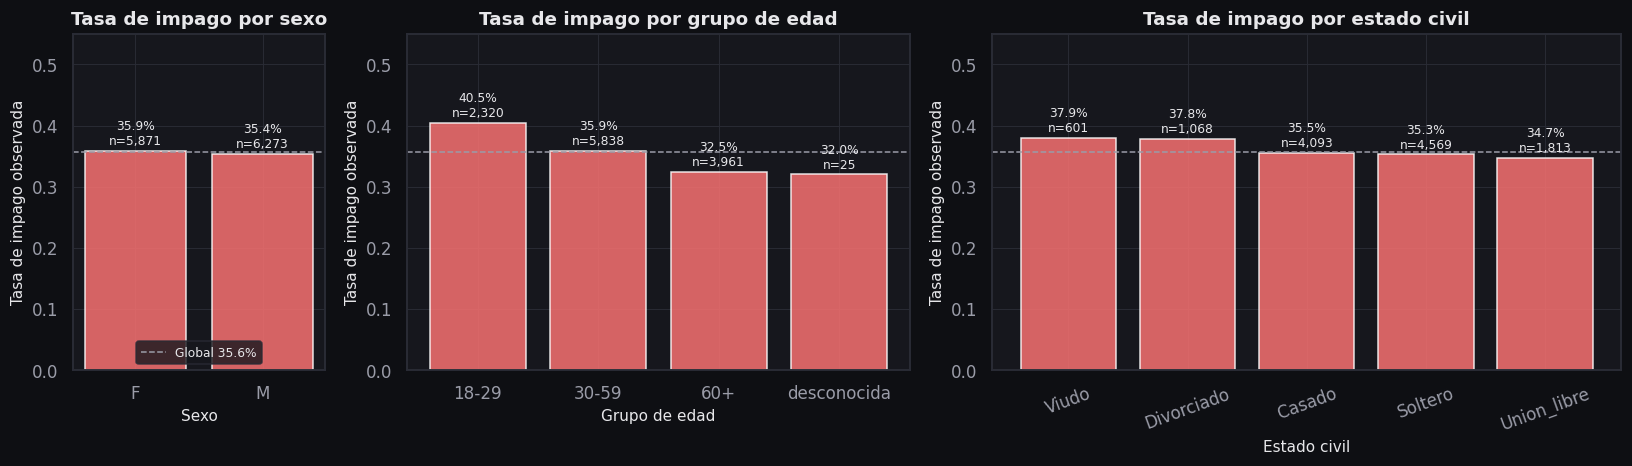

clientes  tasa_impago
atributo      grupo                             
sexo          F                5871       0.3589
              M                6273       0.3539
grupo de edad 18-29            2320       0.4047
              30-59            5838       0.3587
              60+              3961       0.3247
              desconocida        25       0.3200
estado civil  Viudo             601       0.3794
              Divorciado       1068       0.3783
              Casado           4093       0.3550
              Soltero          4569       0.3528
              Union_libre      1813       0.3475

In [12]:
edad_valida = df["edad"].where(df["edad"].between(*config.EDAD_VALIDA))
base = df.assign(grupo_edad=grupo_edad(edad_valida))
tasa_global = df[config.TARGET].mean()
orden_edad = [*config.GRUPOS_EDAD_LABELS, config.GRUPO_EDAD_DESCONOCIDO]
tablas = {
    "sexo": base.groupby(config.SENSITIVE_COL)[config.TARGET].agg(clientes="size", tasa_impago="mean"),
    "grupo de edad": (base.groupby("grupo_edad")[config.TARGET].agg(clientes="size", tasa_impago="mean")
                      .reindex([g for g in orden_edad if g in set(base["grupo_edad"])])),
    "estado civil": base.groupby("estado_civil")[config.TARGET].agg(clientes="size", tasa_impago="mean")
                    .sort_values("tasa_impago", ascending=False),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [2, 4, 5]})
for ax, (nombre, t) in zip(axes, tablas.items()):
    barras = ax.bar(t.index.astype(str), t["tasa_impago"], color=PALETA["impago"], alpha=0.85)
    ax.axhline(tasa_global, color=PALETA["texto_suave"], ls="--", lw=1, label=f"Global {tasa_global:.1%}")
    for b, (tasa, n) in zip(barras, t[["tasa_impago", "clientes"]].itertuples(index=False)):
        ax.text(b.get_x() + b.get_width() / 2, tasa + 0.01, f"{tasa:.1%}\nn={n:,}", ha="center", fontsize=8,
                color=PALETA["texto"])
    ax.set(title=f"Tasa de impago por {nombre}", xlabel=nombre.capitalize(), ylabel="Tasa de impago observada",
           ylim=(0, max(0.55, t["tasa_impago"].max() + 0.12)))
    ax.tick_params(axis="x", labelrotation=20 if nombre == "estado civil" else 0)
axes[0].legend(fontsize=8, loc="lower center")
plt.show()
for nombre, t in tablas.items():
    figura_front("barras", f"Tasa de impago observada por {nombre}",
                 {"categorias": t.index.astype(str).tolist(),
                  "series": [{"nombre": "Tasa de impago", "valores": t["tasa_impago"].round(4).tolist()}],
                  "n": t["clientes"].astype(int).tolist(),
                  "referencias": [{"eje": "y", "valor": round(float(tasa_global), 4), "etiqueta": "Tasa global"}]},
                 ejes={"x": nombre.capitalize(), "y": "Tasa de impago observada"},
                 clave=f"impago_crudo_por_{nombre.replace(' ', '_')}", opciones={"formato_y": "pct"})
pd.concat({k: v for k, v in tablas.items()}, names=["atributo", "grupo"]).round(4)

**Interpretación.** Por **sexo** la tasa de impago es casi idéntica (F 35,9 % frente a M 35,4 %: 0,5 puntos),
coherente con que el generador no usa el sexo para producir `default`. Por **edad** hay un gradiente claro:
40,5 % en 18-29, 35,9 % en 30-59 y 32,5 % en 60+ (8,0 puntos entre el grupo más joven y el mayor). Un modelo
que aprenda ese patrón aprobará automáticamente con menos frecuencia a los jóvenes, así que la edad es el
atributo que más riesgo de *disparate impact* tiene y el que justifica evaluar las variantes `sin_edad` y
*reweighing* en el paso 8. El grupo `desconocida` (las 25 edades inválidas) tiene n < 30 y no contará para el
DI. Por **estado civil** las diferencias son menores (de 34,8 % en Union_libre a 37,9 % en Viudo).

In [13]:
t_sexo, t_edad = tablas["sexo"], tablas["grupo de edad"]
validos = t_edad.drop(index=config.GRUPO_EDAD_DESCONOCIDO, errors="ignore")
display(Markdown(f"""
**Resumen calculado.**

- Dataset: **{df.shape[0]:,} filas × {df.shape[1]} columnas**; tasa de impago **{tasa_global:.2%}**;
  contrato de datos {'**cumplido**' if chequeos['ok'] else '**no cumplido**'}
  ({sum(bool(v) for k, v in chequeos.items() if k not in ('ok', 'columnas_faltantes'))} de
  {sum(1 for k in chequeos if k not in ('ok', 'columnas_faltantes'))} chequeos en verdadero).
- Política de costos: aprobar si p < **{UMBRALES.aprobar:.4f}**, rechazar si p > **{UMBRALES.rechazar:.4f}**,
  revisar en medio; umbral de dos acciones **{UMBRALES.bayes:.2f}**.
- Impago observado por sexo: {', '.join(f'{g} {r:.1%}' for g, r in t_sexo['tasa_impago'].items())}
  (diferencia de {abs(t_sexo['tasa_impago'].max() - t_sexo['tasa_impago'].min()) * 100:.1f} puntos).
- Impago observado por grupo de edad: {', '.join(f'{g} {r:.1%} (n={int(n):,})' for g, n, r in zip(t_edad.index, t_edad['clientes'], t_edad['tasa_impago']))};
  entre grupos válidos hay {(validos['tasa_impago'].max() - validos['tasa_impago'].min()) * 100:.1f} puntos de diferencia.
"""))


**Resumen calculado.**

- Dataset: **12,144 filas × 21 columnas**; tasa de impago **35.63%**;
  contrato de datos **cumplido**
  (10 de
  10 chequeos en verdadero).
- Política de costos: aprobar si p < **0.1778**, rechazar si p > **0.4667**,
  revisar en medio; umbral de dos acciones **0.25**.
- Impago observado por sexo: F 35.9%, M 35.4%
  (diferencia de 0.5 puntos).
- Impago observado por grupo de edad: 18-29 40.5% (n=2,320), 30-59 35.9% (n=5,838), 60+ 32.5% (n=3,961), desconocida 32.0% (n=25);
  entre grupos válidos hay 8.0 puntos de diferencia.


## Conclusiones

- **Problema (F1, E5):** clasificación binaria supervisada que estima la probabilidad de impago (`default`)
  de una solicitud y la convierte en una acción para el analista: **aprobar** si p < 0,1778, **rechazar** si
  p > 0,4667 y **revisar** en medio. Los umbrales salen de los costos del ADR-002 (C_FN 0,45, C_FP 0,15,
  C_R 0,08) y las bandas Bajo/Medio/Alto coinciden con las acciones por construcción.
- **Datos (IA1.1):** `credit_risk.csv` tiene **12.144 filas × 21 columnas** y una tasa de impago del
  **35,63 %** (4.327 impagos y 7.817 pagos); cumple los 10 chequeos del contrato de datos. Se eligió frente a
  German Credit, Default of Credit Card Clients y Give Me Some Credit porque es el único con texto en español,
  sexo, edad y estado civil por separado e imperfecciones realistas para la limpieza.
- **Métricas:** ROC-AUC como principal (meta **≥ 0,70 en test**), con recall, F1, KS y Brier como
  secundarias. El Brier importa porque la regla de Chow supone probabilidades calibradas, y el criterio de
  negocio para elegir variante es el costo esperado por solicitud.
- **Ética (IA1.3):** `sexo` queda fuera del modelo y solo se usa para auditar; la tabla de variables
  sensibles quedó en `Back/reports/variables_sensibles.json` para el paso 8. En los datos crudos el impago
  casi no varía por sexo (0,5 puntos) ni mucho por estado civil, pero sí por **edad** (40,5 % en 18-29 frente
  a 32,5 % en 60+): ese es el riesgo de equidad que el paso 8 debe medir con el DI de la aprobación
  automática y mitigar sin umbrales distintos por grupo.